> **日本語版について**: このノートブックは、[jpmorganchase/python-training](https://github.com/jpmorganchase/python-training) の英語原文を日本語に翻訳したものです（Apache License 2.0）。コードの動作は原文から変更していません。

# 金融データを使う例 #1：アルトマンZスコア（ダブルプライム）の計算

アルトマン教授が「Zスコア」を定式化したのは、NYU 在籍中の [1968年](http://www.defaultrisk.com/_pdf6j4/Financial_Ratios_Discriminant_Anlss_n_Prdctn_o_Crprt_Bnkrptc.pdf) です。Zスコアは、企業がデフォルトする可能性を数値で表す指標です。

その後、何度か改良がありました。企業の信用リスクをよりよく表すため、アルトマンZスコア（ダブルプライム）が生まれました。このモデルは、[アルトマン教授のプレゼンテーション資料](http://pages.stern.nyu.edu/~ealtman/3-%20CopCrScoringModels.pdf) でも解説されています。

当初の目安は大まかなものでした。2.6 を超えれば「健全」。1.1〜2.6 は「グレーゾーン」。1.1 未満は倒産のリスクあり、という分け方です。その後、判定基準はさらに細かく見直されました。

今の Zスコア（ダブルプライム）には、もう1つ特徴があります。通常の信用格付けに対応づけられることです。

以下では、[Alpha Vantage のデータ](https://www.alphavantage.co/documentation/#fundamentals) を使って、スコアを一から計算します。元の例では IEX Cloud API を使っていましたが、2024年8月にサービスが終了しました。

$$ Z” = 6.56x_1 +3.26x_2 + 6.72x_3 + 1.05x_4 $$
$$ \textrm{ここで:} $$
$$ x_1 = \textrm{運転資本 / 総資産} $$
$$ x_2 = \textrm{利益剰余金 / 総資産} $$
$$ x_3 = \textrm{EBIT（利払前・税引前利益）/ 総資産} $$
$$ x_4 = \textrm{株式時価総額 / 負債総額} $$

**補足（日本語版独自の解説）: このあとのコードの進み方**

式だけでは計算の流れが分からないので、先に全体像を書いておきます。

1. Alpha Vantage の API から、IBM の損益計算書・貸借対照表・時価総額を取得する
2. 財務の数値を、上の式の $x_1$〜$x_4$ に当てはめる
3. 係数（6.56、3.26、6.72、1.05）を掛けて合計し、Z'' を出す
4. 計算を関数にまとめ、最後に Z'' から通常の信用格付けへの換算も行う

In [1]:
import os
import time
import requests

ALPHA_VANTAGE_BASE_URL = "https://www.alphavantage.co/query"
# Alpha Vantage の公開 "demo" キーはそのまま使えます。
# ただし実データが返るのは、下で使う "IBM" のみです。
# demo キーは共有のため、1秒あたり数リクエストまでに制限されます。
# 他のティッカーを使う場合や上限を上げる場合は、無料キーを取得してください。
# 取得先: https://www.alphavantage.co/support/#api-key
# キーはコードに直書きせず、環境変数で設定します:
#   export ALPHA_VANTAGE_API_KEY=your_key_here
ALPHA_VANTAGE_API_KEY = os.environ.get("ALPHA_VANTAGE_API_KEY", "demo")

def av_fundamentals(function, ticker):
    '''Alpha Vantage のファンダメンタルズを取得します（OVERVIEW、INCOME_STATEMENT、BALANCE_SHEET）。'''
    time.sleep(0.6)  # レート制限対策で少し待つ
    response = requests.get(
        ALPHA_VANTAGE_BASE_URL,
        params={"function": function, "symbol": ticker, "apikey": ALPHA_VANTAGE_API_KEY},
    )
    response.raise_for_status()
    return response.json()

In [2]:
ticker = "IBM"  # demo キーで実データが返るのは IBM のみ。他のティッカーは自分のキーで
incomeStatement = av_fundamentals("INCOME_STATEMENT", ticker)["annualReports"][0]
balanceSheet = av_fundamentals("BALANCE_SHEET", ticker)["annualReports"][0]
stats = av_fundamentals("OVERVIEW", ticker)

In [3]:
x1 = ( float(balanceSheet["totalCurrentAssets"]) - float(balanceSheet["totalCurrentLiabilities"]) ) / float(balanceSheet["totalAssets"])

In [4]:
x2 = float(balanceSheet["retainedEarnings"]) / float(balanceSheet["totalAssets"])

In [5]:
x3 = float(incomeStatement["ebit"]) / float(balanceSheet["totalAssets"])

In [6]:
x4 = float(stats["MarketCapitalization"]) / float(balanceSheet["totalLiabilities"])

In [7]:
6.56 * x1 + 3.26 * x2 + 6.72 * x3 + 1.05 * x4

5.812582061871934

In [8]:
def altmanZDoublePrime( ticker ):
    '''
    アルトマンZスコア（ダブルプライム）を計算します。

    ticker = 文字列。計算するティッカー。
    デフォルトの "demo" キーで実データが返るのは "IBM" のみです。
    他のティッカーでは、環境変数 ALPHA_VANTAGE_API_KEY に自分の無料キーを設定してください。
    キーは https://www.alphavantage.co/support/#api-key で取得できます。
    '''
    incomeStatement = av_fundamentals("INCOME_STATEMENT", ticker)["annualReports"][0]
    balanceSheet = av_fundamentals("BALANCE_SHEET", ticker)["annualReports"][0]
    stats = av_fundamentals("OVERVIEW", ticker)
    x1 = ( float(balanceSheet["totalCurrentAssets"]) - float(balanceSheet["totalCurrentLiabilities"]) ) / float(balanceSheet["totalAssets"])
    x2 = float(balanceSheet["retainedEarnings"]) / float(balanceSheet["totalAssets"])
    x3 = float(incomeStatement["ebit"]) / float(balanceSheet["totalAssets"])
    x4 = float(stats["MarketCapitalization"]) / float(balanceSheet["totalLiabilities"])
    return 6.56 * x1 + 3.26 * x2 + 6.72 * x3 + 1.05 * x4

In [9]:
altmanZDoublePrime("IBM")

5.812582061871934

**追加実装（日本語版独自）: 計算の内訳を見る**

Z'' の数値だけでは、どの要素が効いているのか分かりません。上の $x_1$〜$x_4$ を使って、寄与の内訳を表にします。

In [10]:
import pandas as pd

components = pd.DataFrame(
    {
        "値": [x1, x2, x3, x4],
        "係数": [6.56, 3.26, 6.72, 1.05],
    },
    index=[
        "x1 運転資本 / 総資産",
        "x2 利益剰余金 / 総資産",
        "x3 EBIT / 総資産",
        "x4 株式時価総額 / 負債総額",
    ],
)
components["寄与"] = components["値"] * components["係数"]
components

,値,係数,寄与
x1 運転資本 / 総資産,-0.018422,6.56,-0.120851
x2 利益剰余金 / 総資産,1.024809,3.26,3.340878
x3 EBIT / 総資産,0.080741,6.72,0.542582
x4 株式時価総額 / 負債総額,1.952356,1.05,2.049974


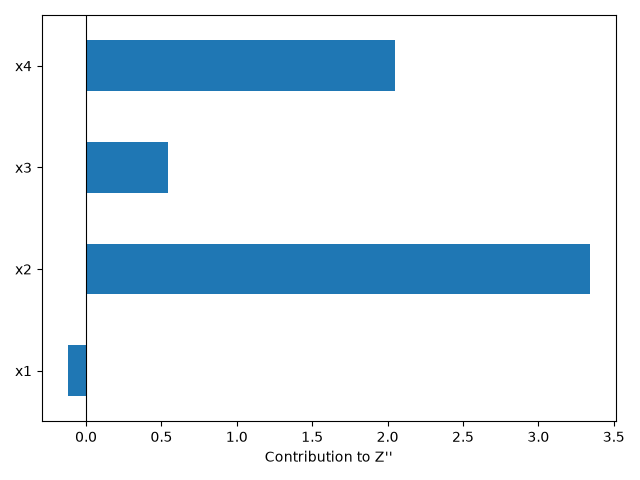

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt

ax = components["寄与"].plot(kind="barh")
ax.set_yticklabels(["x1", "x2", "x3", "x4"])
plt.xlabel("Contribution to Z''")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


**補足（日本語版独自の解説）: 格付けへの換算**

次の関数 `altmanZDPImpliedRating` は、Z'' に 3.25 を足した値を、格付けごとの境界値の表（AAA 側の 8.15 から D 側の 1.75 まで）と照らし合わせ、対応する格付けを返します。

本文の目安（2.6 を超えれば健全、1.1 未満は危険）とは別に、格付けの形で水準を示すための仕組みです。

In [12]:
import numpy as np

def altmanZDPImpliedRating( ticker ):
    '''
    アルトマンZスコア（ダブルプライム）から、対応する信用格付けを求めます。

    ticker = 文字列。Zスコアを計算するティッカー。大文字・小文字は区別しません。
    '''
    adjZScore = 3.25 + altmanZDoublePrime( ticker )
    zMap = [ 8.15, 7.6, 7.3, 7., 6.85, 6.65, 6.4, 6.25, 5.85, 5.65, 5.25, 4.95, 4.75, 4.5, 4.15, 3.75, 3.2, 2.5, 1.75 ]
    scores = [ "AAA", "AA+", "AA", "AA-", "A+", "A", "A-", "BBB+", "BBB", "BBB-", "BB+", "BB", "BB-", "B+", "B", "B-", "CCC+", "CCC", "CCC-", "D" ] 
    return scores[ zMap.index( np.array( zMap )[ np.array( zMap ) < adjZScore ].max() ) ]

In [13]:
altmanZDPImpliedRating("IBM")

'AAA'

**追加実装（日本語版独自）: APIキーなしで計算する（SEC EDGAR）**

原文の方法では、IBM 以外の企業を計算するには Alpha Vantage の自分のキーが必要です。ここでは、キーなしで誰でも使える公的データベース、米証券取引委員会（SEC）の EDGAR から同じ材料を取り、他の企業でも計算できるようにします。EDGAR は上場企業の開示書類そのものを公開しているので、登録もキーも要りません。

原文の計算との違いは2つです。

- $x_4$ は、株価を使う時価総額ではなく、自己資本の簿価 ÷ 負債総額で計算します。Z'' モデル本来の定義はこちらで、EDGAR だけで材料がそろう利点もあります
- EBIT は、項目がある企業では営業利益（OperatingIncomeLoss）を使い、ない企業では「税引前利益 ＋ 支払利息」で近似します

数値は開示書類の申告そのままなので、Alpha Vantage の正規化データとは細部が異なり、結果も完全には一致しません。

なお、SEC のフェアアクセス方針により、アクセスの際は User-Agent で名前とメールアドレスを名乗る必要があります。これはキーや登録とは別で、SEC 側が求める作法です。コードでは環境変数 `SEC_USER_AGENT` から読むようにしてあります。


In [14]:
import os

import requests

# SEC のフェアアクセス方針で、利用者を表す User-Agent（名前とメールアドレス）を名乗る必要があります
# 実行前に、環境変数 SEC_USER_AGENT へ自分のものを設定してください（例: "Your Name you@example.com"）
SEC_HEADERS = {"User-Agent": os.environ.get("SEC_USER_AGENT", "Your Name you@example.com")}


def sec_cik(ticker):
    tickers = requests.get(
        "https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS
    ).json()
    for row in tickers.values():
        if row["ticker"] == ticker:
            return row["cik_str"]
    raise ValueError(ticker)


def sec_latest(cik, concept, taxonomy="us-gaap"):
    url = f"https://data.sec.gov/api/xbrl/companyconcept/CIK{cik:010d}/{taxonomy}/{concept}.json"
    data = requests.get(url, headers=SEC_HEADERS).json()
    units = data["units"]
    values = units[list(units.keys())[0]]
    annual = [v for v in values if v.get("form") in ("10-K", "10-K/A") and v.get("fp") == "FY"]
    annual.sort(key=lambda v: (v["end"], v.get("filed", "")))
    return annual[-1]["val"]


In [15]:
def altman_z_double_prime_edgar(ticker):
    cik = sec_cik(ticker)
    total_assets = sec_latest(cik, "Assets")
    x1 = (sec_latest(cik, "AssetsCurrent") - sec_latest(cik, "LiabilitiesCurrent")) / total_assets
    x2 = sec_latest(cik, "RetainedEarningsAccumulatedDeficit") / total_assets
    try:
        ebit = sec_latest(cik, "OperatingIncomeLoss")
    except Exception:
        ebit = (
            sec_latest(cik, "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest")
            + sec_latest(cik, "InterestExpense")
        )
    x3 = ebit / total_assets
    x4 = sec_latest(cik, "StockholdersEquity") / sec_latest(cik, "Liabilities")
    return 6.56 * x1 + 3.26 * x2 + 6.72 * x3 + 1.05 * x4


def implied_rating(z):
    adj_z = 3.25 + z
    z_map = [8.15, 7.6, 7.3, 7.0, 6.85, 6.65, 6.4, 6.25, 5.85, 5.65, 5.25, 4.95, 4.75, 4.5, 4.15, 3.75, 3.2, 2.5, 1.75]
    scores = ["AAA", "AA+", "AA", "AA-", "A+", "A", "A-", "BBB+", "BBB", "BBB-", "BB+", "BB", "BB-", "B+", "B", "B-", "CCC+", "CCC", "CCC-", "D"]
    return scores[z_map.index(np.array(z_map)[np.array(z_map) < adj_z].max())]


for ticker in ["IBM", "AAPL"]:
    z = altman_z_double_prime_edgar(ticker)
    print(ticker, "Z'' =", round(z, 3), " / 対応格付け:", implied_rating(z))

IBM Z'' = 4.097  / 対応格付け: AA


AAPL Z'' = 3.202  / 対応格付け: A-


IBM は原文の計算と見比べられます。$x_4$ の定義とデータの正規化が違うため、値は近づきますが一致はしません。どちらの値が正しいかではなく、「どの定義で、どのデータを取ったか」で結果が動くこと自体が、この種の指標を読むときの注意点です。